In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052



FOLD 1/5
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 13.6M/13.6M [00:00<00:00, 115MB/s] 
100%|██████████| 40/40 [00:20<00:00,  1.98it/s]


Epoch [1/50] Train Loss: 0.4817 (CE: 0.5950, Dice: 0.3684), Train Acc: 0.6687 | Val Loss: 0.7212 (CE: 0.8305, Dice: 0.6118), Val Acc: 0.6047
  -> Saving best model (Val Accuracy: 0.6047)


100%|██████████| 40/40 [00:16<00:00,  2.36it/s]


Epoch [2/50] Train Loss: 0.4363 (CE: 0.5256, Dice: 0.3470), Train Acc: 0.6906 | Val Loss: 0.5996 (CE: 0.6091, Dice: 0.5901), Val Acc: 0.6062
  -> Saving best model (Val Accuracy: 0.6062)


...

Epoch [8/50] Train Loss: 0.4008 (CE: 0.4838, Dice: 0.3177), Train Acc: 0.7285 | Val Loss: 0.5953 (CE: 0.5810, Dice: 0.6095), Val Acc: 0.6031
  -> No improvement for 7/8 epochs


100%|██████████| 40/40 [00:17<00:00,  2.31it/s]


Epoch [9/50] Train Loss: 0.4043 (CE: 0.4864, Dice: 0.3223), Train Acc: 0.7227 | Val Loss: 0.5650 (CE: 0.5322, Dice: 0.5978), Val Acc: 0.6562
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 9. Best Val Accuracy: 0.6844

Fold 5 Best Validation Accuracy: 0.6844

5-FOLD CROSS-VALIDATION RESULTS
Fold 1 Validation Accuracy: 0.7047
Fold 2 Validation Accuracy: 0.6937
Fold 3 Validation Accuracy: 0.7500
Fold 4 Validation Accuracy: 0.7500
Fold 5 Validation Accuracy: 0.6844

Mean CV Accuracy: 0.7166
CV Standard Deviation: 0.0280
Best CV Accuracy: 0.7500


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



Final Test Loss: 0.4519 (CE: 0.3802, Dice: 0.5235), Final Test Accuracy: 0.8719

Test Precision (weighted): 0.8776
Test Recall (weighted):    0.8719
Test F1-score (weighted):  0.8626

Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.86      0.98      0.92      1052
  Appears normal       0.92      0.60      0.73       416

        accuracy                           0.87      1468
       macro avg       0.89      0.79      0.82      1468
    weighted avg       0.88      0.87      0.86      1468



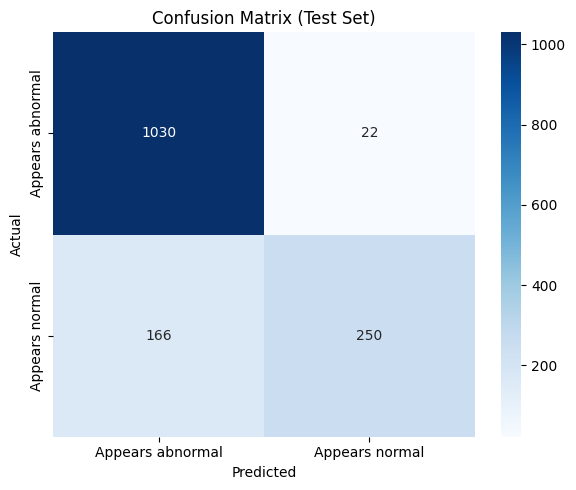


Summary:
Mean 5-Fold CV Accuracy: 0.7166
CV Standard Deviation: 0.0280
Best CV Accuracy: 0.7500
Final Test Accuracy (evaluated once, held-out set): 0.8719
Final Test Precision: 0.8776, Recall: 0.8719, F1: 0.8626
Final Test Dice Loss: 0.5235


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import KFold
import seaborn as sns

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)

# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

num_classes = len(train_dataset.classes)

# Store results from each fold
fold_accuracies = []

# Store best model across all folds
overall_best_accuracy = 0.0
best_model_path = "Mobilenet_1410=.pkl"

# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)
        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)
        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)

        dice_score = (2. * intersection + self.smooth) / \
                     (union + self.smooth)

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# Combined CrossEntropy + Dice Loss
class CombinedLoss(nn.Module):
    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)

        total = self.ce_weight * ce + self.dice_weight * dice

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Evaluation function
# ============================================================

def evaluate_model(model, loader):
    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images, labels = images.to(device), labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(outputs, labels)

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images, labels = images.to(device), labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds


# ============================================================
# CROSS VALIDATION
# ============================================================

for fold, (train_indices, val_indices) in enumerate(
        kfold.split(train_dataset), 1):

    print("\n" + "=" * 60)
    print(f"FOLD {fold}/5")
    print("=" * 60)

    # Create train and validation subsets
    train_subset = Subset(train_dataset, train_indices)
    val_subset = Subset(train_dataset, val_indices)

    # ========================================================
    # Weighted Random Sampler
    # ========================================================

    train_targets = [
        train_dataset.targets[i]
        for i in train_indices
    ]

    class_counts = np.bincount(train_targets)

    class_weights = 1. / class_counts

    sample_weights = [
        class_weights[label]
        for label in train_targets
    ]

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(train_subset),
        replacement=True
    )

    train_loader = DataLoader(
        train_subset,
        batch_size=64,
        sampler=sampler
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=64,
        shuffle=False
    )

    # ========================================================
    # Fresh MobileNetV2 for EACH fold
    # ========================================================

    mobilenet = models.mobilenet_v2(pretrained=True)

    mobilenet.classifier[1] = nn.Linear(
        mobilenet.classifier[1].in_features,
        num_classes
    )

    mobilenet = mobilenet.to(device)

    optimizer = optim.Adam(
        mobilenet.parameters(),
        lr=0.001
    )

    # ========================================================
    # Early stopping setup
    # ========================================================

    best_accuracy = 0.0

    patience = 8
    epochs_no_improve = 0
    max_epochs = 50

    train_losses, train_accs = [], []
    val_losses, val_accs = [], []

    train_ce_losses, train_dice_losses = [], []
    val_ce_losses, val_dice_losses = [], []

    # ========================================================
    # Training
    # ========================================================

    for epoch in range(max_epochs):

        mobilenet.train()

        running_loss = 0.0
        running_ce = 0.0
        running_dice = 0.0

        correct_train = 0
        total_train = 0

        for images, labels in tqdm(train_loader):

            images, labels = images.to(device), labels.to(device)

            outputs = mobilenet(images)

            loss, ce, dice = criterion(outputs, labels)

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total_train += labels.size(0)

            correct_train += (
                predicted == labels
            ).sum().item()

        train_accuracy = correct_train / total_train

        n_batches = len(train_loader)

        train_loss = running_loss / n_batches
        train_ce = running_ce / n_batches
        train_dice = running_dice / n_batches

        # ====================================================
        # Validation
        # ====================================================

        val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
            mobilenet,
            val_loader
        )

        train_losses.append(train_loss)
        train_accs.append(train_accuracy)

        val_losses.append(val_loss)
        val_accs.append(val_accuracy)

        train_ce_losses.append(train_ce)
        train_dice_losses.append(train_dice)

        val_ce_losses.append(val_ce)
        val_dice_losses.append(val_dice)

        print(
            f'Epoch [{epoch+1}/{max_epochs}] '
            f'Train Loss: {train_loss:.4f} '
            f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
            f'Train Acc: {train_accuracy:.4f} | '
            f'Val Loss: {val_loss:.4f} '
            f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
            f'Val Acc: {val_accuracy:.4f}'
        )

        # ====================================================
        # Early stopping
        # ====================================================

        if val_accuracy > best_accuracy:

            best_accuracy = val_accuracy
            epochs_no_improve = 0

            print(
                f'  -> Saving best model '
                f'(Val Accuracy: {best_accuracy:.4f})'
            )

            # Save best model of this fold temporarily
            fold_model_path = f"fold_{fold}_best.pkl"

            torch.save(
                mobilenet.state_dict(),
                fold_model_path
            )

            # Save overall best model
            if val_accuracy > overall_best_accuracy:

                overall_best_accuracy = val_accuracy

                torch.save(
                    mobilenet.state_dict(),
                    best_model_path
                )

        else:

            epochs_no_improve += 1

            print(
                f'  -> No improvement for '
                f'{epochs_no_improve}/{patience} epochs'
            )

        if epochs_no_improve >= patience:

            print(
                f'\nEarly stopping triggered at '
                f'epoch {epoch+1}. '
                f'Best Val Accuracy: {best_accuracy:.4f}'
            )

            break

    # ========================================================
    # Fold result
    # ========================================================

    fold_accuracies.append(best_accuracy)

    print(
        f'\nFold {fold} Best Validation Accuracy: '
        f'{best_accuracy:.4f}'
    )


# ============================================================
# 5-FOLD CV SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 60)

for i, acc in enumerate(fold_accuracies, 1):

    print(
        f"Fold {i} Validation Accuracy: {acc:.4f}"
    )

mean_cv_accuracy = np.mean(fold_accuracies)
std_cv_accuracy = np.std(fold_accuracies)

print(
    f"\nMean CV Accuracy: {mean_cv_accuracy:.4f}"
)

print(
    f"CV Standard Deviation: {std_cv_accuracy:.4f}"
)

print(
    f"Best CV Accuracy: {overall_best_accuracy:.4f}"
)


# ============================================================
# Load BEST model from the 5 folds
# ============================================================

best_mobilenet_model = models.mobilenet_v2(
    pretrained=False
)

best_mobilenet_model.classifier[1] = nn.Linear(
    best_mobilenet_model.classifier[1].in_features,
    num_classes
)

best_mobilenet_model = best_mobilenet_model.to(device)

best_mobilenet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# TEST SET
# IMPORTANT: Test is untouched during cross-validation
# ============================================================

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_mobilenet_model,
    test_loader
)

print(
    f'\nFinal Test Loss: {test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final Test Accuracy: {test_accuracy:.4f}'
)


# ============================================================
# Test Precision, Recall, F1
# ============================================================

true_labels, pred_labels = get_predictions(
    best_mobilenet_model,
    test_loader
)

class_names = train_dataset.classes

precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)

recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)

print(
    f'\nTest Precision (weighted): {precision:.4f}'
)

print(
    f'Test Recall (weighted):    {recall:.4f}'
)

print(
    f'Test F1-score (weighted):  {f1:.4f}'
)


# ============================================================
# Classification Report
# ============================================================

print('\nPer-class report:')

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title('Confusion Matrix (Test Set)')

plt.tight_layout()

plt.show()


# ============================================================
# Summary
# ============================================================

print(f'\nSummary:')

print(
    f'Mean 5-Fold CV Accuracy: '
    f'{mean_cv_accuracy:.4f}'
)

print(
    f'CV Standard Deviation: '
    f'{std_cv_accuracy:.4f}'
)

print(
    f'Best CV Accuracy: '
    f'{overall_best_accuracy:.4f}'
)

print(
    f'Final Test Accuracy '
    f'(evaluated once, held-out set): '
    f'{test_accuracy:.4f}'
)

print(
    f'Final Test Precision: '
    f'{precision:.4f}, '
    f'Recall: {recall:.4f}, '
    f'F1: {f1:.4f}'
)

print(
    f'Final Test Dice Loss: '
    f'{test_dice:.4f}'
)

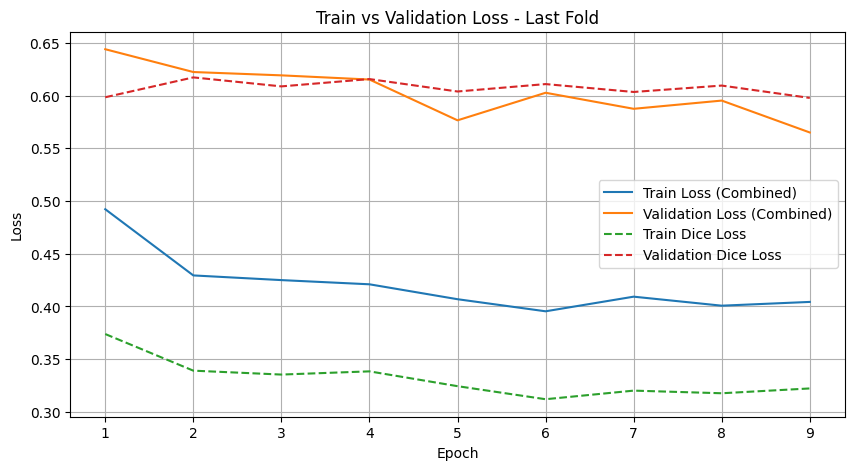

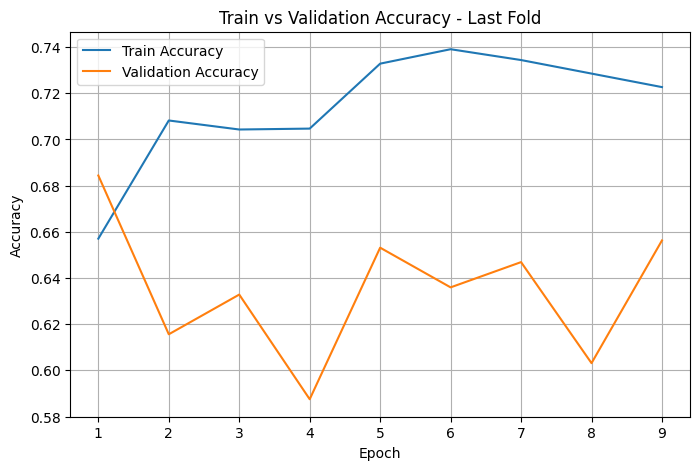

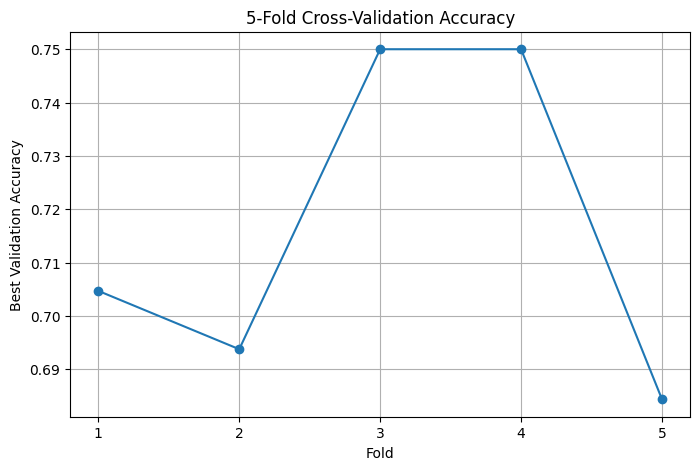

In [5]:
# ============================================================
# GRAPHS - LAST FOLD
# ============================================================

epochs_range = range(1, len(train_losses) + 1)

# Train vs Validation Loss
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Validation Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Validation Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss - Last Fold')
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# Train vs Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train vs Validation Accuracy - Last Fold')
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 5-Fold Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

fold_numbers = range(1, len(fold_accuracies) + 1)

plt.plot(
    fold_numbers,
    fold_accuracies,
    marker='o'
)

plt.xlabel('Fold')
plt.ylabel('Best Validation Accuracy')
plt.title('5-Fold Cross-Validation Accuracy')

plt.xticks(fold_numbers)
plt.grid(True)

plt.show()